# 15 · Đánh giá v1 và v2: so hai model, và độ nhạy với thời gian không quan sát

Checkpoint 2 yêu cầu **benchmark hai model**: v1 (chấm từng stay, notebook 12–13) và v2 (gộp stay thành nơi bằng DBSCAN, notebook 14). Notebook 14 đã so **độ ổn định** split-half (v2 62% / 62%, v1 41% / 42%). Notebook này trả lời thêm hai câu hỏi trên toàn bộ dữ liệu, bằng **chính code của `src/`**:

1. **v1 và v2 khác nhau ở đâu?** Bao nhiêu user hai model trả cùng một home / office, bao nhiêu khác chỗ, và khi khác thì vì sao.
2. **Kết quả có phụ thuộc vào thời gian không quan sát không?** Một stay kéo dài từ lúc đến tới lúc đi (`duration_minutes`), nhưng bên trong có thể có những khoảng thiết bị không ghi điểm nào (> 20 phút). Notebook 06 quyết định **không** cắt stay ở những khoảng này, và hứa rằng phía dùng stay sẽ kiểm tra độ nhạy (`observed_minutes`). Ở đây: nếu chỉ tính phút **có quan sát** trong khung giờ, home / office có đổi không?

**Không có nhãn home/office**, nên cả hai câu hỏi đo **sự khác biệt và độ nhạy**, không đo độ đúng. Độ đúng sẽ được ước lượng bằng một đợt chấm tay mù trên mẫu 40 user (phần sau).

Mọi CI được bootstrap theo **nhóm user dùng chung file** (notebook 11).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK = "15_classifier_evaluation"
DATA_DIR = Path("../data/raw")
OUT_DIR = Path("outputs") / NOTEBOOK
FIG_DIR, TABLE_DIR, CACHE_DIR, MAP_DIR = (OUT_DIR / d for d in ("figures", "tables", "cache", "maps"))
for d in (FIG_DIR, TABLE_DIR, CACHE_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(Path("../src").resolve()))
from gps.models.cluster import ClusterClassifier, place_labels
from gps.models.heuristic import HeuristicClassifier

STAY_DIR = Path("../data/processed/staypoints")
USER_DIR = Path("../data/processed/users")
SHARED_PAIRS = Path("outputs/11_shared_recordings/tables/shared_pairs.csv")
NEAR_M = 200                         # "cùng một chỗ" = bán kính stay-point (notebook 07)
EARTH_M = 6_371_008.8
UNOBSERVED = pd.Timedelta(seconds=1200)   # = StayPointDetector.unobserved_gap_seconds (notebook 06)
TYPES = ("home", "office")
v1, v2 = HeuristicClassifier(), ClusterClassifier()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
rng = np.random.default_rng(15)

## 1. Dữ liệu
- Stay ≥ 30 phút (`min_duration_minutes`) của 174 user có stay; 8 user không có stay nào luôn là unknown ở cả hai model và không nằm trong các bảng dưới.
- Với mỗi stay, số phút trong khung được tách **theo từng ngày** (đêm của ngày *d* = 22 h ngày *d* → 08 h ngày *d*+1; ngày làm việc = 09–18 h thứ 2–6), bằng chính vòng lặp `HeuristicClassifier._daily_overlaps` của `src/`. Hai cách tính:
  - `duration`: toàn bộ khoảng từ lúc đến tới lúc đi (cách `src/` đang làm);
  - `observed`: trừ đi mọi khoảng trống > 20 phút giữa hai điểm GPS liên tiếp **bên trong** stay. Khoảng trống lấy từ điểm sạch thật của pipeline (`data/processed/users/`), không nội suy.
- Giờ địa phương của khoảng trống dùng độ lệch múi giờ của stay (lúc đến), giống `arrival_local`.

In [2]:
paths = sorted(STAY_DIR.glob("user_*.parquet"))
stays = pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)
stays["user_id"] = stays["user_id"].astype(str).str.zfill(3)
stays = stays[stays["duration_minutes"] >= v1.min_duration_minutes].reset_index(drop=True)
offset = stays["arrival_local"] - stays["arrival"]

GAP_CACHE = CACHE_DIR / "gaps_inside_stays.parquet"
if GAP_CACHE.exists():
    gaps = pd.read_parquet(GAP_CACHE)
else:
    rows = []
    for u, g in stays.groupby("user_id"):
        t = pd.read_parquet(USER_DIR / f"user_{u}.parquet", columns=["datetime"])["datetime"].sort_values().to_numpy()
        for sid, a, d in zip(g.index, g["arrival"].to_numpy(), g["departure"].to_numpy()):
            seg = t[np.searchsorted(t, a, "left"):np.searchsorted(t, d, "right")]
            big = np.flatnonzero(np.diff(seg) > UNOBSERVED.to_timedelta64())
            rows += [(sid, seg[i], seg[i + 1]) for i in big]
    gaps = pd.DataFrame(rows, columns=["sid", "gap_start", "gap_end"])
    gaps.to_parquet(GAP_CACHE)


def daily(arr_local, dep_local):
    """{ngày: [phút home, phút office]} của khoảng [arr_local, dep_local)."""
    return {d: np.array([h, o]) for d, h, o in v1._daily_overlaps(arr_local, dep_local) if h or o}


DUR, OBS = [], []
gaps_by_sid = gaps.groupby("sid")
for sid, (a, d, off) in enumerate(zip(stays["arrival_local"], stays["departure_local"], offset)):
    dur = daily(a.to_pydatetime(), d.to_pydatetime())
    obs = {k: v.copy() for k, v in dur.items()}
    if sid in gaps_by_sid.groups:
        for gs, ge in gaps_by_sid.get_group(sid)[["gap_start", "gap_end"]].itertuples(index=False):
            for k, v in daily((gs + off).to_pydatetime(), (ge + off).to_pydatetime()).items():
                obs[k] = obs[k] - v
    DUR.append(dur)
    obs = {k: np.clip(np.round(v, 6), 0, None) for k, v in obs.items()}
    OBS.append({k: v for k, v in obs.items() if v.max() > 0})

tot_dur = np.array([sum(x.values(), np.zeros(2)) for x in DUR])
tot_obs = np.array([sum(x.values(), np.zeros(2)) for x in OBS])
print(f"Stays >= 30 min: {len(stays):,} of {stays['user_id'].nunique()} users; gaps > 20 min inside stays: {len(gaps):,} "
      f"in {gaps['sid'].nunique():,} stays")
print(f"Check: duration-based home/office minutes equal src window_minutes: "
      f"{np.allclose(tot_dur, [v1.window_minutes(a.to_pydatetime(), d.to_pydatetime()) for a, d in zip(stays['arrival_local'], stays['departure_local'])])}")
print(f"Unobserved share of window minutes, all stays: home {1 - tot_obs[:, 0].sum() / tot_dur[:, 0].sum():.1%}, "
      f"office {1 - tot_obs[:, 1].sum() / tot_dur[:, 1].sum():.1%}")

Stays >= 30 min: 18,597 of 174 users; gaps > 20 min inside stays: 16,014 in 14,430 stays


Check: duration-based home/office minutes equal src window_minutes: True
Unobserved share of window minutes, all stays: home 93.6%, office 87.8%


## 2. Tái hiện v1 và v2 của `src/` trong notebook
Để đổi được cách tính phút (`duration` → `observed`), notebook cần tự chạy luật chọn của hai model trên một bảng phút cho trước. Hai hàm dưới viết lại đúng luật của `src/`:
- **v1** (`HeuristicClassifier`): stay thắng = nhiều phút trong khung nhất (hoà: stay dài hơn, rồi đến sớm hơn); unknown khi < 240 phút hoặc `support` < 2 (ứng viên trong 200 m, kể cả chính nó).
- **v2** (`ClusterClassifier`): nơi = cụm `place_labels` (DBSCAN 150 m, `min_samples` 2, nhiễu là nơi riêng); nơi thắng = tổng phút cao nhất (hoà: tổng thời lượng dài hơn, rồi đến sớm hơn); unknown khi < 240 phút hoặc có phút trong khung ở < 2 ngày.

Ô thứ hai so kết quả `duration` của notebook với `predict` của `src/` cho mọi user: trạng thái, lý do, số phút, `support`, và vị trí.

In [3]:
pairs = pd.read_csv(SHARED_PAIRS, dtype=str)
parent = {}


def root(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


for a, b in zip(pairs["user_a"], pairs["user_b"]):
    parent[root(a)] = root(b)
USERS = {u: g.index.to_numpy() for u, g in stays.groupby("user_id")}
GROUP = {u: root(u) for u in USERS}


def dist_m(lat1, lon1, lat2, lon2):
    la1, lo1, la2, lo2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * EARTH_M * np.arcsin(np.sqrt(h))


LAT, LON = stays["lat"].to_numpy(), stays["lon"].to_numpy()
DURM = stays["duration_minutes"].to_numpy()
ARR = stays["arrival"].astype("int64").to_numpy()
LABELS = {u: place_labels(LAT[ix], LON[ix], v2.eps_meters, v2.min_samples) for u, ix in USERS.items()}
K = {"home": 0, "office": 1}


def result(status, reason=None, minutes=None, support=None, lat=None, lon=None, member=None):
    return {"status": status, "reason": reason, "window_minutes": minutes, "support": support,
            "lat": lat, "lon": lon, "members": member}


def run_v1(ix, table, kind):
    m = np.array([sum(table[i].values(), np.zeros(2))[K[kind]] for i in ix])
    cand = np.flatnonzero(m > 0)
    if not len(cand):
        return result("unknown", "no_candidate")
    best = cand[np.lexsort((ARR[ix][cand], -DURM[ix][cand], -m[cand]))[0]]
    support = int((dist_m(LAT[ix][best], LON[ix][best], LAT[ix][cand], LON[ix][cand]) <= v1.support_radius_m).sum())
    reason = ("too_few_window_minutes" if m[best] < v1.min_window_minutes
              else "one_off_place" if support < v1.min_support else None)
    return result("unknown" if reason else "found", reason, m[best], support, LAT[ix][best], LON[ix][best], [ix[best]])


def run_v2(ix, table, labels, kind):
    k = K[kind]
    m = np.array([sum(table[i].values(), np.zeros(2))[k] for i in ix])
    P = labels.max() + 1
    score = np.bincount(labels, weights=m, minlength=P)
    cand = np.flatnonzero(score > 0)
    if not len(cand):
        return result("unknown", "no_candidate")
    tot = np.bincount(labels, weights=DURM[ix], minlength=P)
    first = np.full(P, np.iinfo(np.int64).max)
    np.minimum.at(first, labels, ARR[ix])
    best = cand[np.lexsort((first[cand], -tot[cand], -score[cand]))[0]]
    sel = labels == best
    days = len({d for i in ix[sel] for d, v in table[i].items() if v[k] > 0})
    lat, lon = np.average(LAT[ix][sel], weights=DURM[ix][sel]), np.average(LON[ix][sel], weights=DURM[ix][sel])
    reason = ("too_few_window_minutes" if score[best] < v2.min_window_minutes
              else "one_off_place" if days < v2.min_window_days else None)
    return result("unknown" if reason else "found", reason, score[best], days, lat, lon, list(ix[sel]))


def run_all(table):
    rows = []
    for u, ix in USERS.items():
        for kind in TYPES:
            rows.append({"user_id": u, "group": GROUP[u], "type": kind, "model": "v1", **run_v1(ix, table, kind)})
            rows.append({"user_id": u, "group": GROUP[u], "type": kind, "model": "v2", **run_v2(ix, table, LABELS[u], kind)})
    return pd.DataFrame(rows)


res = {"duration": run_all(DUR), "observed": run_all(OBS)}

In [4]:
def missing(x):
    return x is None or (isinstance(x, float) and np.isnan(x))


bad = 0
for u, ix in USERS.items():
    records = stays.loc[ix, ["lat", "lon", "arrival", "departure"]].to_dict("records")
    for model, clf in (("v1", v1), ("v2", v2)):
        out = clf.predict(records)
        for kind in TYPES:
            st, loc = getattr(out, f"{kind}_status"), getattr(out, kind)
            r = res["duration"].query("user_id == @u and type == @kind and model == @model").iloc[0]
            same = (st.status == r["status"] and missing(st.reason) == missing(r["reason"])
                    and (missing(st.reason) or st.reason == r["reason"])
                    and missing(st.support) == missing(r["support"])
                    and (missing(st.support) or st.support == r["support"])
                    and (missing(st.window_minutes) or np.isclose(st.window_minutes, r["window_minutes"])))
            if loc is not None:
                same &= bool(np.isclose(loc.lat, r["lat"]) and np.isclose(loc.lon, r["lon"]))
            bad += not same
print(f"(user, type, model) cases where the notebook differs from src predict: {bad} of {len(USERS) * 4}")

(user, type, model) cases where the notebook differs from src predict: 0 of 696


## 3. v1 và v2 khác nhau ở đâu?
**Trạng thái.** Bảng chéo trạng thái v1 × v2 cho từng loại (cách tính `duration`, tức là đúng `src/`).

In [5]:
d = res["duration"]
wide = d.pivot_table(index=["user_id", "group", "type"], columns="model",
                     values=["status", "reason", "lat", "lon", "window_minutes", "support"], aggfunc="first")
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide = wide.reset_index()
cross = pd.crosstab([wide["type"], wide["status_v1"]], wide["status_v2"], margins=True)
cross.to_csv(TABLE_DIR / "status_v1_vs_v2.csv")
reasons = pd.crosstab([wide["type"], wide["reason_v1"].fillna("found")], wide["reason_v2"].fillna("found"))
reasons.to_csv(TABLE_DIR / "reason_v1_vs_v2.csv")
display(cross)
reasons

status_v2         found  unknown  All
type   status_v1                     
home   found        104        0  104
       unknown       10       60   70
office found         92        8  100
       unknown       16       58   74
All                 222      126  348

reason_v2                      found  no_candidate  one_off_place  \
type   reason_v1                                                    
home   found                     104             0              0   
       no_candidate                0            10              0   
       one_off_place               6             0             22   
       too_few_window_minutes      4             0              2   
office found                      92             0              8   
       no_candidate                0            15              0   
       one_off_place              11             0             15   
       too_few_window_minutes      5             0              1   

reason_v2                      too_few_window_minutes  
type   reason_v1                                       
home   found                                        0  
       no_candidate                                 0  
       one_off_place                                0  
       too_few_window_minutes                      26  
office found                                        0  
       no_candidate                                 0  
       one_off_place                                0  
       too_few_window_minutes                      27

**v1 trả lời nhưng v2 không.** Với các trường hợp này, so `support` của v1 (số stay trong 200 m) với `support` của v2 (số ngày có phút trong khung tại nơi đó), và đếm số **ngày khác nhau** của các stay mà v1 tính vào `support`.

In [6]:
only_v1 = wide[(wide["status_v1"] == "found") & (wide["status_v2"] != "found")].copy()


def v1_support_days(u, kind):
    ix = USERS[u]
    r = d.query("user_id == @u and type == @kind and model == 'v1'").iloc[0]
    near = [i for i in ix if sum(DUR[i].values(), np.zeros(2))[K[kind]] > 0
            and dist_m(r["lat"], r["lon"], LAT[i], LON[i]) <= v1.support_radius_m]
    return len({day for i in near for day, v in DUR[i].items() if v[K[kind]] > 0})


only_v1["v1_support_distinct_days"] = [v1_support_days(u, k) for u, k in zip(only_v1["user_id"], only_v1["type"])]
only_v1[["user_id", "type", "reason_v2", "support_v1", "v1_support_distinct_days", "support_v2", "window_minutes_v1",
         "window_minutes_v2"]]

,user_id,type,reason_v2,support_v1,v1_support_distinct_days,support_v2,window_minutes_v1,window_minutes_v2
95,047,office,one_off_place,2.0,1,1.0,332.900000,332.900000
115,058,office,one_off_place,2.0,1,1.0,376.866667,376.866667
117,059,office,one_off_place,2.0,1,1.0,376.866667,376.866667
147,076,office,one_off_place,2.0,2,1.0,491.716667,491.716667
223,114,office,one_off_place,2.0,2,1.0,466.866667,466.866667
237,122,office,one_off_place,2.0,1,1.0,298.816667,380.066667
247,127,office,one_off_place,2.0,1,1.0,321.683333,489.300000
311,161,office,one_off_place,2.0,2,1.0,436.033333,436.033333


**Vị trí.** Với các user mà **cả hai** model trả lời, home (office) của hai model cách nhau bao xa? "Cùng chỗ" = ≤ 200 m. Phân loại các trường hợp khác chỗ:
- `v1 stay inside v2 place`: stay thắng của v1 là một stay **thuộc** nơi thắng của v2, nhưng tâm nơi (có trọng số thời lượng) cách stay đó > 200 m. Hai model nói về cùng một nơi, chỉ khác điểm đại diện.
- `different place`: stay thắng của v1 thuộc một nơi khác. Cột `v1_place_rank` cho biết nơi chứa stay của v1 đứng thứ mấy theo điểm của v2.

In [7]:
both = wide[(wide["status_v1"] == "found") & (wide["status_v2"] == "found")].copy()
both["dist_m"] = dist_m(both["lat_v1"].astype(float), both["lon_v1"].astype(float),
                        both["lat_v2"].astype(float), both["lon_v2"].astype(float))
members = d[d["model"] == "v2"].set_index(["user_id", "type"])["members"]
winner_v1 = d[d["model"] == "v1"].set_index(["user_id", "type"])["members"]


def v1_place_rank(u, kind):
    ix, lab = USERS[u], LABELS[u]
    m = np.array([sum(DUR[i].values(), np.zeros(2))[K[kind]] for i in ix])
    score = np.bincount(lab, weights=m)
    place = lab[list(ix).index(winner_v1[(u, kind)][0])]
    return int((score > score[place]).sum()) + 1


both["v1_in_v2_place"] = [winner_v1[(u, k)][0] in members[(u, k)] for u, k in zip(both["user_id"], both["type"])]
both["v1_place_rank"] = [v1_place_rank(u, k) for u, k in zip(both["user_id"], both["type"])]
both["category"] = np.select([both["dist_m"] <= NEAR_M, both["v1_in_v2_place"]],
                             ["same place (<= 200 m)", "v1 stay inside v2 place"], "different place")


def boot_share(x, groups, n=2000):
    gs = pd.DataFrame({"x": x.astype(float), "g": groups}).groupby("g")["x"].agg(["sum", "size"])
    s, k = gs["sum"].to_numpy(), gs["size"].to_numpy(float)
    idx = rng.integers(0, len(gs), (n, len(gs)))
    b = s[idx].sum(1) / k[idx].sum(1)
    return s.sum() / k.sum(), np.quantile(b, 0.025), np.quantile(b, 0.975)


rows = []
for kind, x in both.groupby("type"):
    p, lo, hi = boot_share(x["category"] == "same place (<= 200 m)", x["group"])
    rows.append({"type": kind, "both_found": len(x), "same_place": p, "ci_lo": lo, "ci_hi": hi,
                 **x["category"].value_counts().to_dict(),
                 "median_dist_m_if_different": x.loc[x["dist_m"] > NEAR_M, "dist_m"].median()})
agree = pd.DataFrame(rows)
agree.round(3).to_csv(TABLE_DIR / "location_agreement.csv", index=False)
display(agree.round(3))
both[both["category"] == "different place"].groupby("type")["v1_place_rank"].value_counts().sort_index()

,type,both_found,same_place,ci_lo,ci_hi,same place (<= 200 m),different place,v1 stay inside v2 place,median_dist_m_if_different
0,home,104,0.76,0.678,0.848,79,22,3,9303.948
1,office,92,0.75,0.659,0.848,69,21,2,5520.026


type    v1_place_rank
home    2                16
        3                 3
        4                 2
        5                 1
office  2                14
        3                 3
        4                 1
        5                 1
        6                 1
        10                1
Name: count, dtype: int64

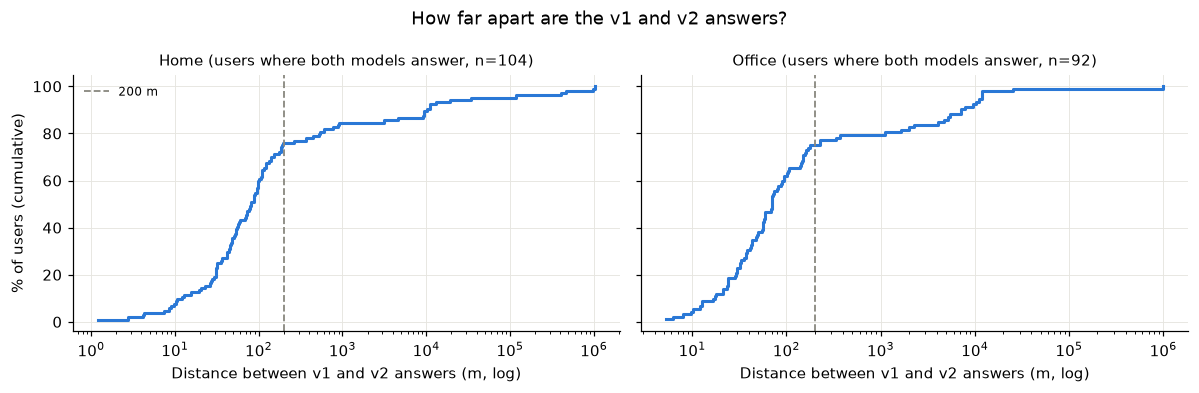

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, kind in zip(axes, TYPES):
    x = np.sort(both.loc[both["type"] == kind, "dist_m"].clip(lower=1))
    ax.step(x, np.arange(1, len(x) + 1) / len(x) * 100, where="post", color="#2a78d6", linewidth=2)
    ax.axvline(NEAR_M, color="#8a8980", linestyle="--", linewidth=1.2, label="200 m")
    ax.set_xscale("log")
    ax.set_xlabel("Distance between v1 and v2 answers (m, log)")
    ax.set_title(f"{kind.capitalize()} (users where both models answer, n={len(x)})", fontsize=10)
axes[0].set_ylabel("% of users (cumulative)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("How far apart are the v1 and v2 answers?")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig01_v1_v2_distance.png")
plt.show()

## 4. Độ nhạy với thời gian không quan sát (`observed` thay cho `duration`)
Trước hết: thời gian không quan sát chiếm bao nhiêu trong số phút trong khung, theo từng user? Một user tắt máy cả đêm ở nhà sẽ có stay qua đêm (nối được nhờ notebook 04) nhưng gần như không có phút **quan sát** nào trong khung home.

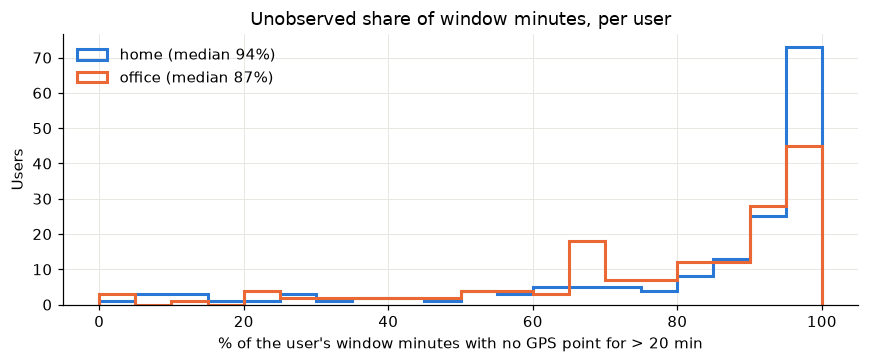

,home_unobserved,office_unobserved
count,164.000,159.000
mean,0.819,0.780
std,0.251,0.239
min,-0.000,-0.000
10%,0.431,0.417
25%,0.753,0.677
50%,0.940,0.866
75%,0.978,0.956
90%,0.997,0.990
max,1.000,1.000


In [9]:
per_user = []
for u, ix in USERS.items():
    td, to = tot_dur[ix].sum(0), tot_obs[ix].sum(0)
    per_user.append({"user_id": u, "home_window_h": td[0] / 60, "office_window_h": td[1] / 60,
                     "home_unobserved": 1 - to[0] / td[0] if td[0] else np.nan,
                     "office_unobserved": 1 - to[1] / td[1] if td[1] else np.nan})
per_user = pd.DataFrame(per_user)
per_user.round(3).to_csv(TABLE_DIR / "unobserved_share_per_user.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 21)
for kind, color in (("home", "#2a78d6"), ("office", "#eb6834")):
    ax.hist(per_user[f"{kind}_unobserved"].dropna() * 100, bins=bins * 100, histtype="step", linewidth=2, color=color,
            label=f"{kind} (median {per_user[f'{kind}_unobserved'].median():.0%})")
ax.set_xlabel("% of the user's window minutes with no GPS point for > 20 min")
ax.set_ylabel("Users")
ax.set_title("Unobserved share of window minutes, per user")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig02_unobserved_share_per_user.png")
plt.show()
per_user[["home_unobserved", "office_unobserved"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3)

**Khoảng trống nằm ở đâu?** Notebook 06 chạy stay-point riêng từng file, nên chỉ đo khoảng trống **bên trong một file**. Từ notebook 04, stay được nối qua các file cách nhau ≤ 18 h, nên còn khoảng trống **giữa hai file**. Ô dưới chia số phút không quan sát theo hai loại này (điểm trước và sau khoảng trống thuộc cùng file hay khác file).

In [10]:
SRC_CACHE = CACHE_DIR / "gap_between_files.parquet"
if SRC_CACHE.exists():
    gaps["between_files"] = pd.read_parquet(SRC_CACHE)["between_files"].to_numpy()
else:
    flag = pd.Series(False, index=gaps.index)
    gaps_user = stays["user_id"].to_numpy()[gaps["sid"]]
    for u, g in gaps.groupby(gaps_user):
        f = pd.read_parquet(USER_DIR / f"user_{u}.parquet", columns=["datetime", "source_file"]).drop_duplicates("datetime")
        f = f.set_index("datetime")["source_file"]
        flag[g.index] = f.reindex(g["gap_start"]).to_numpy() != f.reindex(g["gap_end"]).to_numpy()
    gaps["between_files"] = flag.to_numpy()
    gaps[["between_files"]].to_parquet(SRC_CACHE)

off = offset.to_numpy()[gaps["sid"]]
wm = np.array([v1.window_minutes((a + o).to_pydatetime(), (b + o).to_pydatetime())
               for a, b, o in zip(gaps["gap_start"], gaps["gap_end"], off)])
gaps["home_min"], gaps["office_min"] = wm[:, 0], wm[:, 1]
gap_kind = gaps.assign(hours=(gaps["gap_end"] - gaps["gap_start"]).dt.total_seconds() / 3600).groupby("between_files").agg(
    gaps=("sid", "size"), median_hours=("hours", "median"), home_min=("home_min", "sum"), office_min=("office_min", "sum"))
for k in ("home_min", "office_min"):
    gap_kind[f"{k}_share"] = gap_kind[k] / gap_kind[k].sum()
gap_kind.index = gap_kind.index.map({False: "inside one file (notebook 06)", True: "between two files (notebook 04)"})
gap_kind.round(3).to_csv(TABLE_DIR / "unobserved_by_gap_kind.csv")
gap_kind.round(3)

,gaps,median_hours,home_min,office_min,home_min_share,office_min_share
between_files,,,,,,
inside one file (notebook 06),9856,0.948,149282.75,358622.933,0.08,0.304
between two files (notebook 04),6158,9.898,1723574.50,822523.150,0.92,0.696


**Kết quả đổi bao nhiêu?** So từng (user, loại, model) giữa hai cách tính:
- `found -> unknown` / `unknown -> found`: trạng thái đổi;
- `moved > 200 m`: cả hai đều trả lời nhưng vị trí cách nhau > 200 m;
- `same`: trạng thái như nhau và (nếu trả lời) vị trí trong 200 m.

In [11]:
a, b = res["duration"], res["observed"]
m = a.merge(b, on=["user_id", "group", "type", "model"], suffixes=("_dur", "_obs"))
moved = (m["status_dur"] == "found") & (m["status_obs"] == "found")
m["dist_m"] = np.where(moved, dist_m(m["lat_dur"].astype(float).fillna(0), m["lon_dur"].astype(float).fillna(0),
                                     m["lat_obs"].astype(float).fillna(0), m["lon_obs"].astype(float).fillna(0)), np.nan)
m["change"] = np.select(
    [(m["status_dur"] == "found") & (m["status_obs"] != "found"),
     (m["status_dur"] != "found") & (m["status_obs"] == "found"),
     moved & (m["dist_m"] > NEAR_M)],
    ["found -> unknown", "unknown -> found", "moved > 200 m"], "same")
changes = pd.crosstab([m["model"], m["type"]], m["change"])
changes["answered_duration"] = m.groupby(["model", "type"])["status_dur"].apply(lambda s: (s == "found").sum())
changes["answered_observed"] = m.groupby(["model", "type"])["status_obs"].apply(lambda s: (s == "found").sum())
changes.to_csv(TABLE_DIR / "observed_vs_duration_changes.csv")
display(changes)
lost = m[m["change"] == "found -> unknown"]
pd.crosstab([lost["model"], lost["type"]], lost["reason_obs"])

change        found -> unknown  moved > 200 m  same  unknown -> found  \
model type                                                              
v1    home                  69             17    87                 1   
      office                89              3    79                 3   
v2    home                  52              8   114                 0   
      office                60             14   100                 0   

change        answered_duration  answered_observed  
model type                                          
v1    home                  104                 36  
      office                100                 14  
v2    home                  114                 62  
      office                108                 48

reason_obs    no_candidate  one_off_place  too_few_window_minutes
model type                                                       
v1    home               4              1                      64
      office             0              0                      89
v2    home               4              1                      47
      office             0              2                      58

## 5. Kết luận (phần so sánh và độ nhạy; độ đúng chờ đợt chấm tay)

**Đã kiểm chứng trên dữ liệu** (174 user có stay, 18.597 stay ≥ 30 phút; CI bootstrap theo nhóm user dùng chung file):

1. **Notebook tái hiện đúng `src/`**: trạng thái, lý do, số phút, `support` và vị trí trùng với `predict` của cả hai model ở 696 / 696 trường hợp (174 user × 2 loại × 2 model).
2. **v2 trả lời mọi home mà v1 trả lời, và thêm 10** (bảng `status_v1_vs_v2.csv`). Office: hai model cùng trả lời 92 user; v2 thêm 16, nhưng bỏ 8 user mà v1 trả lời.
   - Trong 8 user đó, v2 trả `one_off_place`: 5 user có `support` = 2 ở v1 nhưng hai stay đó **cùng một ngày**; 3 user còn lại có stay thứ hai trong vòng 200 m của v1 nhưng ngoài cụm 150 m của v2. Đây là khác biệt có chủ đích: notebook 14 đổi cách đếm từ số stay sang số ngày.
3. **Khi cả hai model cùng trả lời, 3/4 trường hợp là cùng một chỗ** (≤ 200 m; bảng `location_agreement.csv`, Hình 1):
   - home 76% (CI 68–85%, 79 / 104), office 75% (CI 66–85%, 69 / 92);
   - các trường hợp khác chỗ là **nơi khác hẳn**, không phải hai điểm của cùng một nơi: trung vị 9,3 km (home), 5,5 km (office); chỉ 3 / 2 trường hợp là stay của v1 nằm trong nơi của v2;
   - nơi v1 chọn thường là **nơi đứng thứ 2** theo điểm của v2 (16 / 22 home, 14 / 21 office). v1 chọn một stay dài nhất, v2 chọn nơi có tổng thời gian lớn nhất; hai thứ này khác nhau khi user có hai nơi ở hoặc hai nơi làm việc.
4. **Home và office gần như hoàn toàn dựa vào thời gian không quan sát** (Hình 2, bảng `unobserved_share_per_user.csv`):
   - trên mọi stay, 93,6% số phút trong khung home và 87,8% số phút trong khung office nằm trong khoảng trống > 20 phút giữa hai điểm GPS;
   - theo user: trung vị 94% (home), 87% (office); chỉ 10% user có dưới 43% / 42%.
   - Lý do: GeoLife ghi **chuyến đi**. Thiết bị thường tắt khi tới nơi và bật lại khi đi tiếp, nên đêm ở nhà và ngày ở chỗ làm là khoảng trống giữa hai lần ghi tại cùng một chỗ.
   - **92%** số phút home không quan sát (office **70%**) nằm trong khoảng trống **giữa hai file** (trung vị 9,9 h), do notebook 04 nối; chỉ 8% / 30% nằm trong khoảng trống **bên trong một file** (trung vị 0,9 h), loại mà notebook 06 đã đo (bảng `unobserved_by_gap_kind.csv`).
5. **Nếu chỉ tính phút có quan sát, phần lớn câu trả lời biến mất** (bảng `observed_vs_duration_changes.csv`):

   | Model | Loại | Trả lời (`duration`) | Trả lời (`observed`) | Còn trả lời nhưng dời > 200 m |
   |---|---|---|---|---|
   | v1 | home | 104 | 36 | 17 / 35 |
   | v1 | office | 100 | 14 | 3 / 11 |
   | v2 | home | 114 | 62 | 8 / 62 |
   | v2 | office | 108 | 48 | 14 / 48 |

   Gần hết trường hợp mất câu trả lời là `too_few_window_minutes`. v2 ít nhạy hơn v1: giữ được nhiều câu trả lời hơn, và trong số còn trả lời thì ít bị dời hơn (home 13% so với 49%).

**Diễn giải:**
- Cách tính `observed` **không phải** một phương án thay thế hợp lệ cho dữ liệu này: nó gần như chỉ đếm thời gian **đang di chuyển hoặc vừa tới nơi**, không đếm thời gian ở lại.
- Cả hai model dựa trên **giả định**: "giữa hai lần ghi bắt đầu và kết thúc ở cùng một chỗ, user ở chỗ đó". Bằng chứng mới phủ một phần nhỏ:
  - khoảng trống bên trong một file (8% phút home, 30% phút office): notebook 06 cho thấy thiết bị bật lại cách chỗ tắt vài chục mét, và chuyến đi có nhãn nằm trọn trong khoảng trống chỉ 0,2–1,9%;
  - khoảng trống giữa hai file (phần lớn): notebook 04 chỉ cho thấy đó là một **nơi quen thuộc** (đêm được nối rơi vào nơi ban đêm đã quan sát 49,5% so với 18,7–24,3%), **không** cho thấy user ở yên suốt khoảng trống. **Chưa kiểm chứng.**
  - Suy luận (chưa đo): vì lần ghi sau bắt đầu ở đúng chỗ lần ghi trước kết thúc, nếu user có rời đi thì cũng đã quay về; sai số nằm ở **số phút** của nơi đó, và chỉ đổi nơi được chọn khi số phút của một nơi bị thổi phồng nhiều hơn nơi khác.

**Đề xuất (chờ duyệt):**
- **Không đổi `src/`.** Giữ cách tính theo `duration`.
- Không làm thêm phép kiểm tra cho khoảng trống giữa hai file (quyết định của user: tập trung vào bài toán phân loại); giả định trên được ghi là chưa kiểm chứng.

**Chưa kiểm chứng:**
- Cả hai phần trên đo **khác biệt và độ nhạy**, không đo **độ đúng**. Khi v1 và v2 khác chỗ, notebook này chưa nói được bên nào đúng. Đợt chấm tay mù 40 user (phân tầng theo: hai model cùng chỗ / khác chỗ / chỉ một model trả lời) sẽ trả lời câu đó.